# Allocentric social place fields — demo

Compute occupancy-normalized rate maps of a focal animal's cells over each
(self and partner) animal's allocentric `(x, y)`, then look at a few example
cells, the population classification, and the **self-position confound control**.

See [`analysis/social_spatial_fields/social_spatial_fields.py`](social_spatial_fields.py) for the API and
the project `README.md` / `CLAUDE.md` for the gotchas. Two that matter most here:

- occupancy is computed over the **target's** `(x, y)`, not the focal animal's;
- tracking↔ephys conversion lives only in
  `video.tracking_import.resolve_tracking_on_ephys_clock`
  (`MultiAnimalSession.get_tracking_on_ephys_clock` is a thin wrapper around it).

Only the focal animal needs ephys, so we load through
`ingestion.focal_session.load_focal_session_inputs` rather than a
`MultiAnimalSession` — the targets contribute tracking trajectories only.

In [1]:
import sys, os
sys.path.append(os.path.abspath('..'))
%matplotlib inline

from ingestion.focal_session import load_focal_session_inputs
from analysis.social_spatial_fields.social_spatial_fields import (
    DEFAULT_STRATUM_RADIUS_CM,
    compare_self_stratum_control,
    compute_social_place_fields,
    modal_occupancy_center,
)
from analysis.social_spatial_fields import social_spatial_plots as sp

## 1. Load a session and compute social place fields

Edit `SESSION`, `ANIMALS`, and `FOCAL` for your data. The focal animal's spikes
generate the maps; every animal in `ANIMALS` (including the focal) is a target.

`n_shuffles` is **not** a free knob. The per-cell FDR family is the targets, so
the smallest reachable q is `n_targets / (n_shuffles + 1)`; with 3–4 targets at
the default `sig_alpha=0.01` anything below ~400 shuffles makes it arithmetically
impossible for any cell to be called tuned, whatever the effect size. 500 is the
smallest safe value here — so don't cut it to save time.

Time is no longer the reason to. The null loop hoists all tracking-side work out
of the iteration and shares it across cells, and `shuffle_split_half` now
defaults to `False` (the split-half *observed* value is still reported; only its
unused shuffle p-value is skipped). Measured together at ~13× on a 7500 s
session.

In [2]:
SESSION = '20251210'
ANIMALS = ['631', '634', '635', '629']
FOCAL = '631'

# Only the focal animal's ephys is loaded; targets contribute tracking only.
inputs = load_focal_session_inputs(SESSION, FOCAL)

results = compute_social_place_fields(
    inputs.ks_focal, inputs.tracking, inputs.sync,
    focal_animal=FOCAL, target_animals=ANIMALS,
    pixels_per_cm=inputs.pixels_per_cm,
    bin_size_cm=5.0, smoothing_sigma_cm=5.0,
    speed_threshold_cms=5.0, speed_filter_subject='target',
    n_shuffles=500,
    null_method='auto',     # circular_shift here; position_shuffle under a stratum
    use_quality_cells=True,
    progress=True,          # bar over cell-target fits
)
print('null used:', results.parameters['null_method'])
results.cell_classification['category'].value_counts()

c:\Users\proskurinm\GitHub\habitat_pipeline\ingestion\trodes_to_python.py:63: FutureWarning: Passing (type, 1) or '1type' as a synonym of type is deprecated; in a future version of numpy, it will be understood as (type, (1,)) / '(1,)type'.
  return np.dtype(typearr)


social fields: focal 631:   0%|          | 0/1508 [00:00<?, ?fit/s]

null used: circular_shift


category
none            368
partner_only      7
self_only         1
broadcast         1
Name: count, dtype: int64

## 2. Rate-map grids for a few example cells

Two rankings, both shown. **Max bits/spike** is the original one — the largest
effect size. **Min `p_skaggs`** is the one to trust for "most convincingly
tuned", because bits/spike is inflated when a rate map rests on few spikes
(measured at ~110× across a 0.15–30 Hz range on *spatially untuned* synthetic
cells), so ranking by it partly ranks the quiet cells. The permutation p-value
is immune: each cell's null is built from its own spike train, so the bias
cancels in the comparison.

The printed overlap between the two lists is the diagnostic — little overlap
means the rate bias is steering the bits ranking on this dataset.

One panel per target animal (the focal target is the self place field). Each
heatmap is the **target's** position, and the white overlay is the **focal**
animal's — both in the same arena coordinates, so a panel reads "target here,
focal there". Without a stratum (below) the focal ranged over the whole arena,
so the overlay is its dwell-time contours with a `+` at its modal bin, and the
title says *position unconditioned*: nothing here rules out that an apparent
partner field is really the focal animal's own place field. Pass
`show_focal=False` to drop the overlay.

top 5 by max bits/spike : [93, 140, 761, 191, 317]
top 5 by min p_skaggs   : [761, 420, 339, 683, 504]
shared: 1/5  (little overlap => the rate bias is driving the bits ranking)


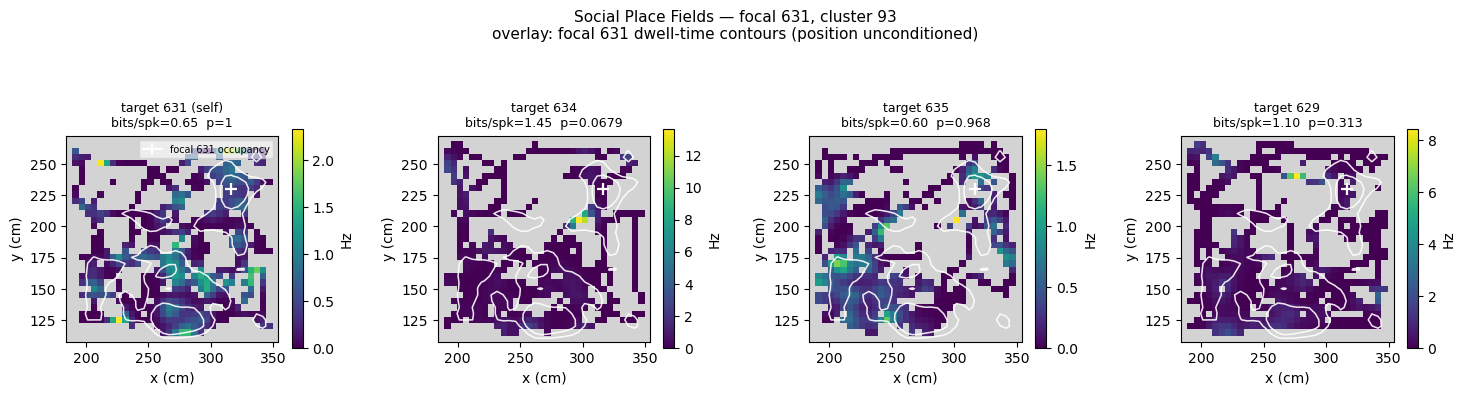

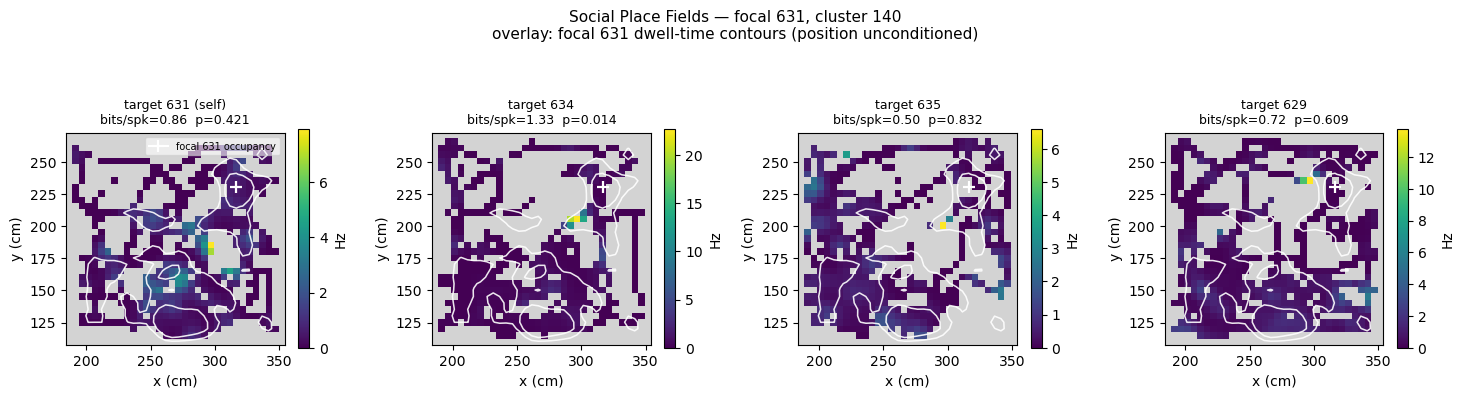

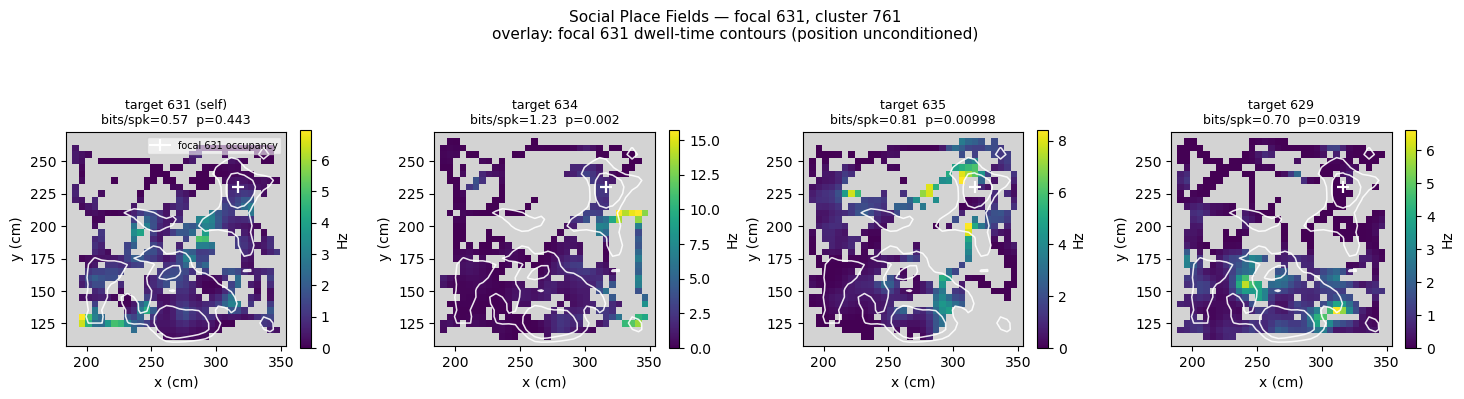

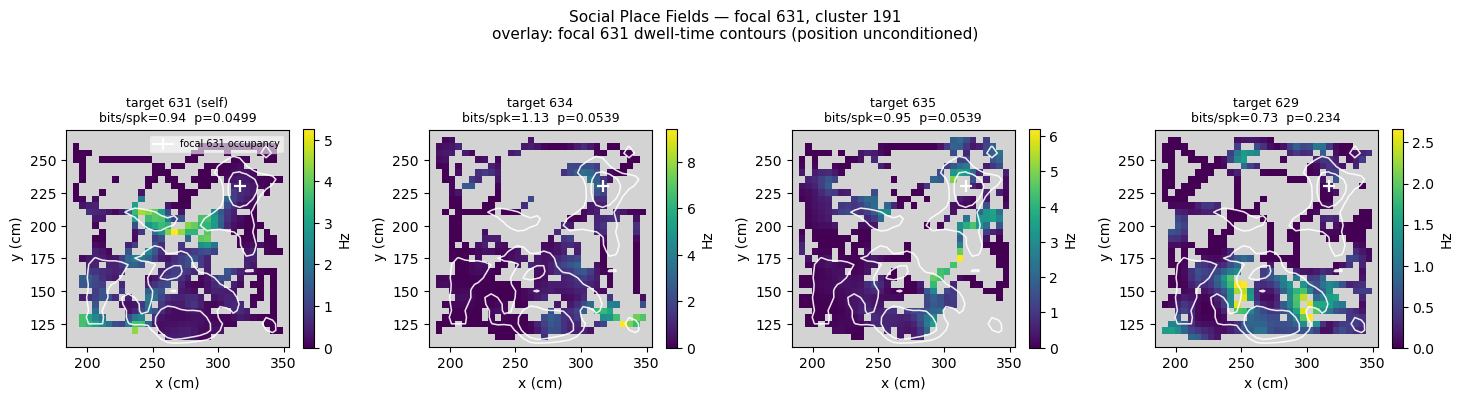

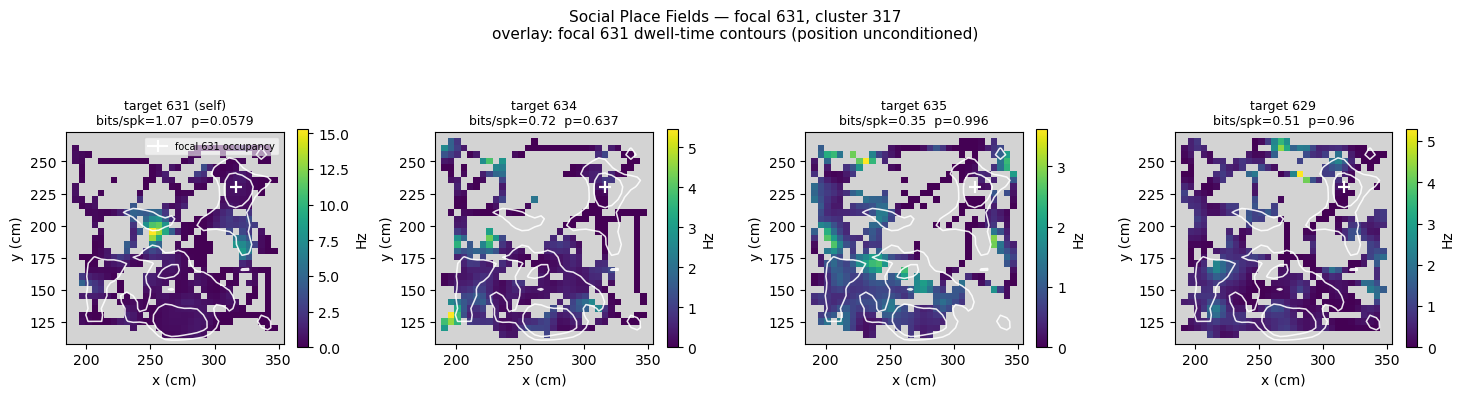

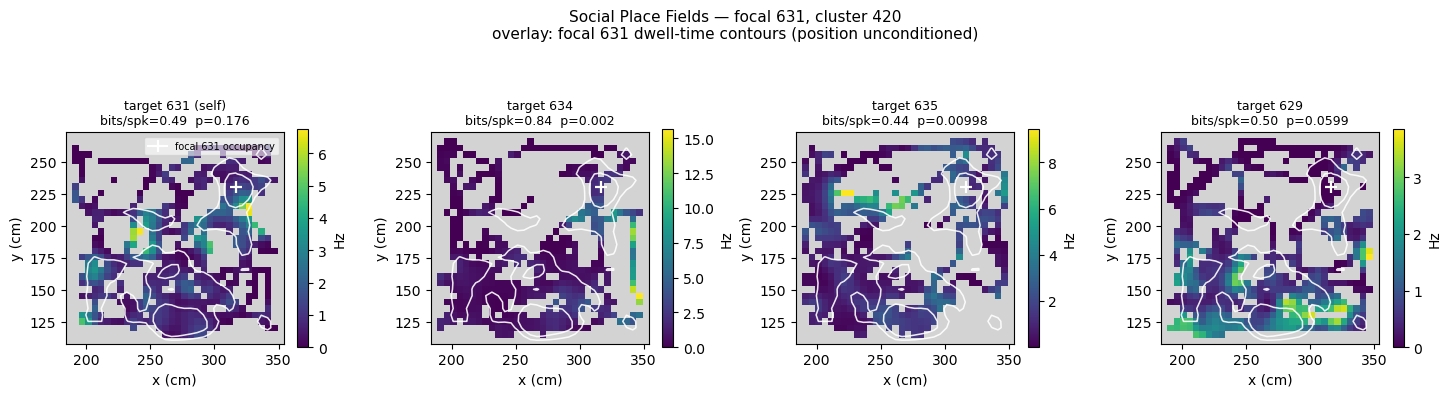

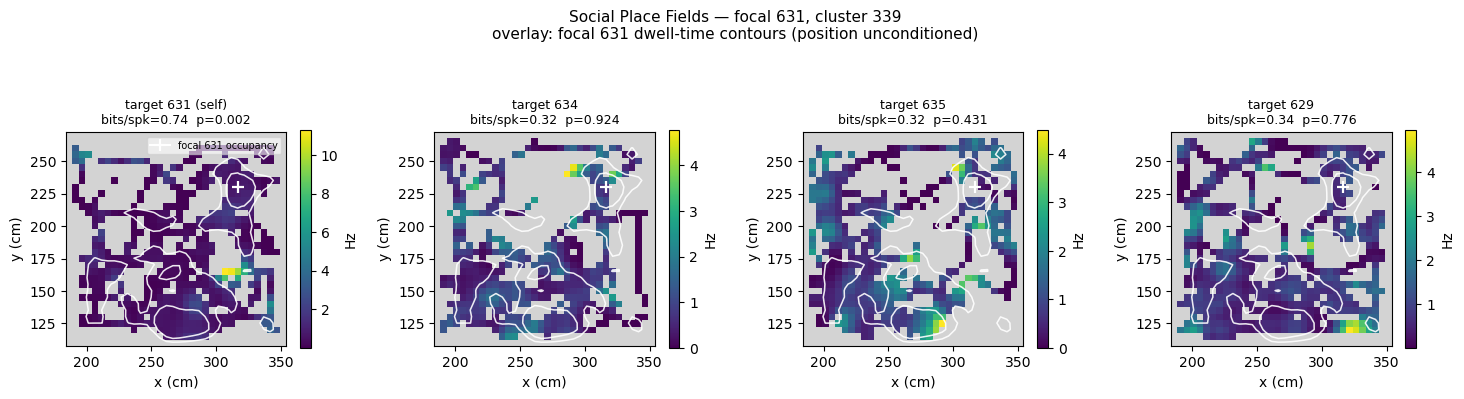

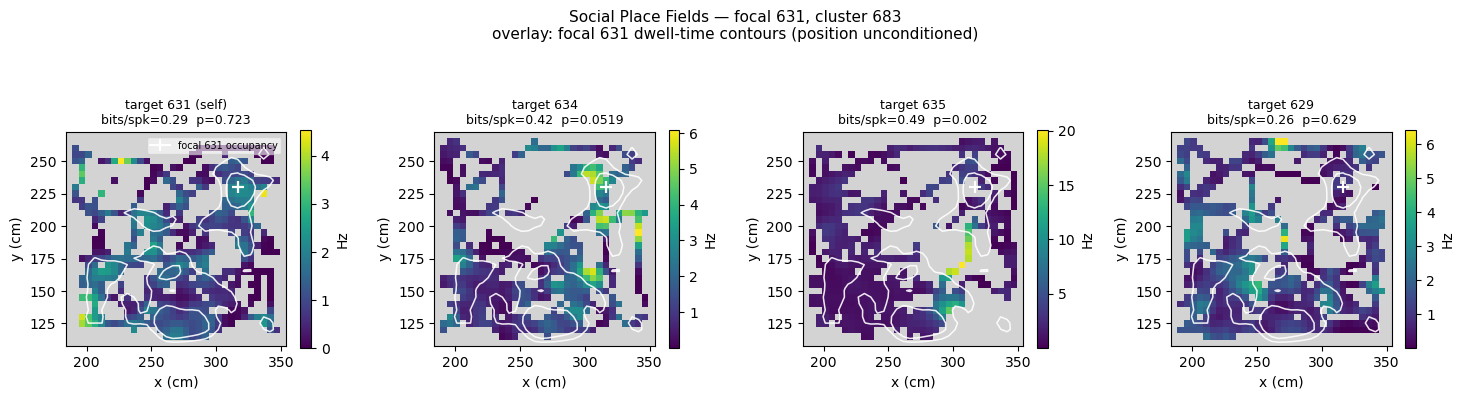

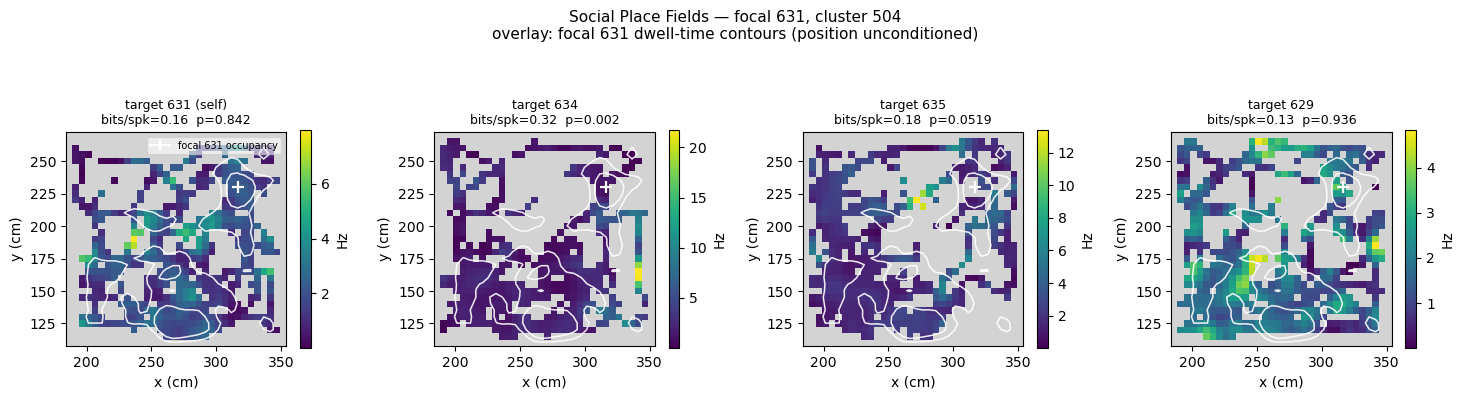

In [4]:
import importlib
importlib.reload(sp)

df = results.cell_classification
bits_cols = [f'bits_per_spike_{t}' for t in ANIMALS if f'bits_per_spike_{t}' in df.columns]
p_cols    = [f'p_value_{t}'        for t in ANIMALS if f'p_value_{t}'        in df.columns]

ranked = df.assign(best_bits=df[bits_cols].max(axis=1),
                   best_p=df[p_cols].min(axis=1))

# (a) Largest effect size — the original ranking. Kept, but read with care:
#     bits/spike is inflated when a map rests on few spikes (~110x across a
#     0.15-30 Hz range on untuned synthetic cells), so this is partly a ranking
#     of the quiet cells. See the bits/spike-vs-rate panel in section 3.
by_bits = ranked.sort_values('best_bits', ascending=False)['cluster_id']

# (b) Most significant. p is floored at 1/(n_shuffles+1) = 0.002 at 500
#     shuffles, so many cells tie at the floor; break ties by effect size.
#     NaN p (below min_n_spikes, never tested) sorts last, not first.
by_p = ranked.sort_values(['best_p', 'best_bits'], ascending=[True, False],
                          na_position='last')['cluster_id']

N_SHOW = 5
top_bits = by_bits.head(N_SHOW).astype(int).tolist()
top_p    = by_p.head(N_SHOW).astype(int).tolist()
print(f'top {N_SHOW} by max bits/spike : {top_bits}')
print(f'top {N_SHOW} by min p_skaggs   : {top_p}')
print(f'shared: {len(set(top_bits) & set(top_p))}/{N_SHOW}'
      '  (little overlap => the rate bias is driving the bits ranking)')

# Union, de-duplicated, so a cell in both lists is not plotted twice.
for cid in dict.fromkeys(top_bits + top_p):
    sp.plot_rate_maps_grid(results, cluster_id=cid)

## 3. Population classification summary

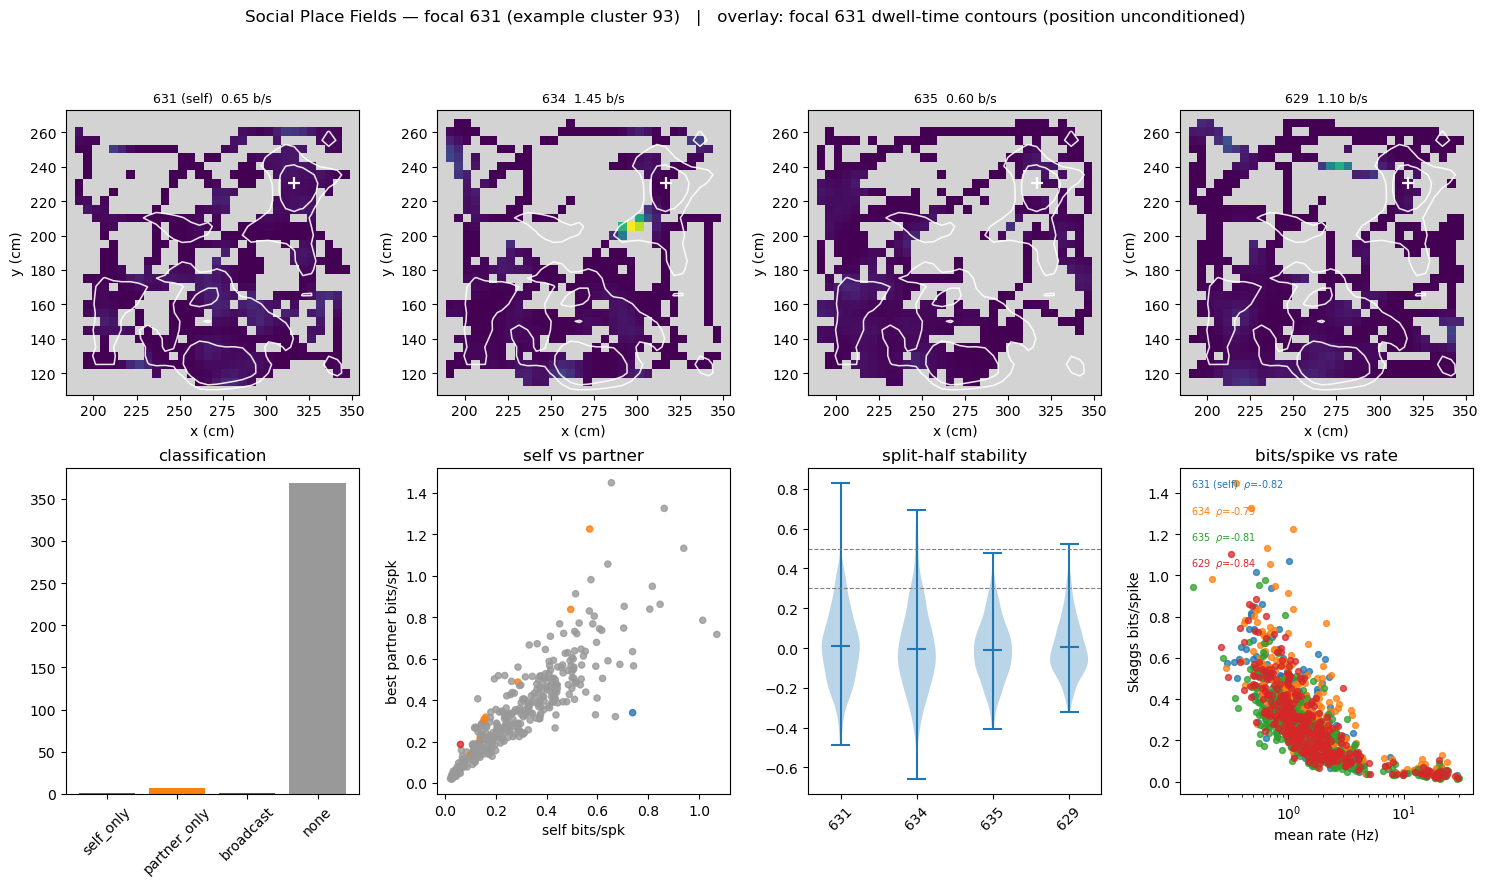

In [5]:
import importlib
importlib.reload(sp)
sp.plot_social_place_summary(results)
# sp.plot_field_stability(results)

## 4. Self-position confound control

The nulls above break the spike↔target-position pairing *entirely*, so what they
reject is "this cell's firing is unrelated in time to the target's position". A
cell that codes only the **focal animal's own** position violates that whenever
the two animals' trajectories are correlated — which is the defining property of
a shared arena. Such a cell is reported as partner-tuned without ever having
represented the partner.

The control is to hold the focal animal still: restrict every map to samples
where it sat within `radius_cm` of one spot, so its own position has almost no
variance and cannot generate a map over the target's position.

`DEFAULT_STRATUM_RADIUS_CM` is deliberately permissive. A radius at place-field
scale (~5 cm) is the tighter control, but it retains under 1% of samples and
starves most cells below `min_n_spikes`, leaving no power to detect a real
partner field. Check `residual_spread_cm` in the diagnostics to see how loose the
control actually ended up, and tighten the radius if the retained budget allows.

In [6]:
RADIUS_CM = DEFAULT_STRATUM_RADIUS_CM   # permissive; tighten if enough data survives

comparison = compare_self_stratum_control(
    inputs.ks_focal, inputs.tracking, inputs.sync,
    focal_animal=FOCAL, target_animals=ANIMALS,
    self_stratum_radius_cm=RADIUS_CM,
    pixels_per_cm=inputs.pixels_per_cm,
    bin_size_cm=5.0, smoothing_sigma_cm=5.0,
    speed_threshold_cms=5.0, speed_filter_subject='target',
    n_shuffles=500, use_quality_cells=True,
    progress=True,          # two bars: unrestricted, then [stratum]
)

# How tight did the control actually end up, and how much data survived?
for target, d in comparison.parameters['self_stratum_diagnostics'].items():
    print(f"{target}: kept {d['n_retained']:>6} samples "
          f"({100 * d['fraction_retained']:5.2f}%), {d['retained_seconds']:7.1f} s, "
          f"focal spread {d['residual_spread_cm']:.2f} cm")

social fields: focal 631:   0%|          | 0/1508 [00:00<?, ?fit/s]

social fields: focal 631 [stratum]:   0%|          | 0/1508 [00:00<?, ?fit/s]

631: kept  16865 samples (23.47%),   421.6 s, focal spread 9.90 cm
634: kept  16865 samples (23.47%),   421.6 s, focal spread 9.90 cm
635: kept  16865 samples (23.48%),   421.6 s, focal spread 9.90 cm
629: kept  16865 samples (23.48%),   421.6 s, focal spread 9.90 cm


### Which partner tuning survives the control?

`lost_to_stratum` flags tests that were significant unrestricted and are not once
the focal animal is pinned — candidate self-position leakage.

Read `n_spikes_stratum` before believing it. A tight stratum starves cells whose
fields sit away from it, and a cell that vanished for want of spikes has not been
shown to be a confound. The **self** target is the positive control and is
*expected* to collapse: the focal is confined by construction.

Compare `p_full` against `p_stratum`, never `bits_full` against `bits_stratum` —
fewer retained spikes bias Skaggs upward through noise while losing real signal
pushes it down, so the two runs are not on a common scale. Each run's
permutation test is still valid, because each builds its null from its own
retained data.

In [7]:
tbl = comparison.table
partners = tbl[~tbl['is_self']]
selfs = tbl[tbl['is_self']]

# 'survives_stratum' alone means "significant in the stratified run", NOT
# "was significant before and still is" — so it must be intersected with
# sig_full, or it counts newly-significant tests too and can exceed sig_full.
kept = partners['sig_full'] & partners['survives_stratum']
newly = ~partners['sig_full'] & partners['survives_stratum']

print(f"partner tests significant unrestricted : {int(partners['sig_full'].sum())}")
print(f"  ... of those, still significant      : {int(kept.sum())}")
print(f"  ... lost (leakage OR spike-starved)  : {int(partners['lost_to_stratum'].sum())}")
print(f"newly significant only under stratum   : {int(newly.sum())}   <- expect few")
print(f"self tests still significant           : {int(selfs['survives_stratum'].sum())}"
      f" / {len(selfs)}   <- positive control, expect ~0")
print(f"median spikes kept, partner tests      : "
      f"{partners['n_spikes_stratum'].median():.0f} of "
      f"{partners['n_spikes_full'].median():.0f}")

cols = ['cluster_id', 'target', 'p_full', 'p_stratum',
        'n_spikes_full', 'n_spikes_stratum', 'survives_stratum']
partners[partners['sig_full']].sort_values('p_stratum')[cols].head(15)

partner tests significant unrestricted : 9
  ... of those, still significant      : 0
  ... lost (leakage OR spike-starved)  : 9
newly significant only under stratum   : 10   <- expect few
self tests still significant           : 0 / 377   <- positive control, expect ~0
median spikes kept, partner tests      : 77 of 447


,cluster_id,target,p_full,p_stratum,n_spikes_full,n_spikes_stratum,survives_stratum
488,420,634,0.001996,0.021956,304,134,False
626,761,634,0.001996,0.021956,297,220,False
1432,868,629,0.001996,0.043912,966,225,False
684,885,634,0.001996,0.049900,811,229,False
520,504,634,0.001996,0.139721,576,202,False
735,993,634,0.001996,0.169661,574,156,False
739,1004,634,0.003992,0.514970,1065,358,False
970,683,635,0.001996,0.692615,619,167,False
1493,1004,629,0.001996,0.848303,1307,312,False


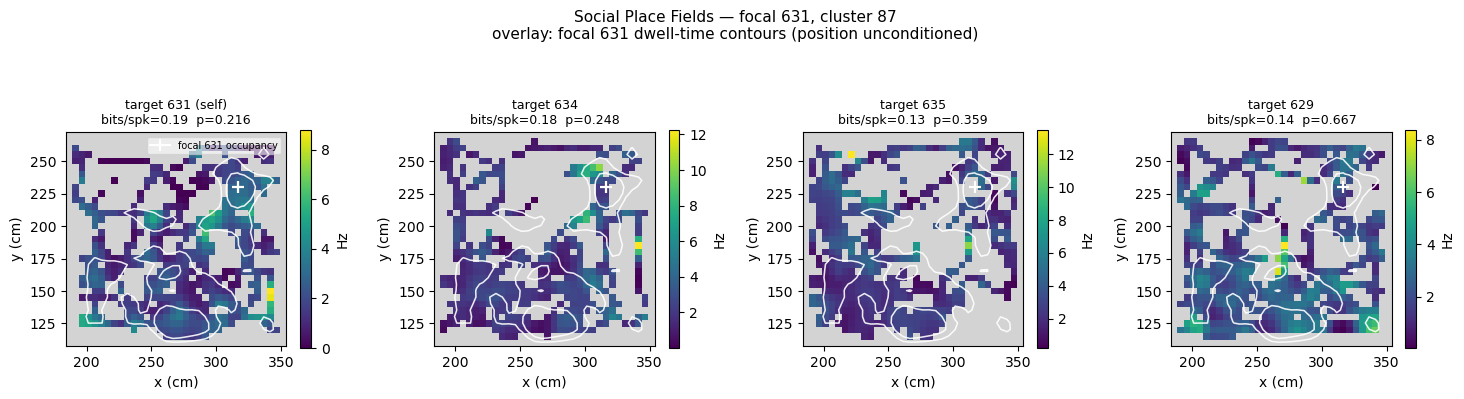

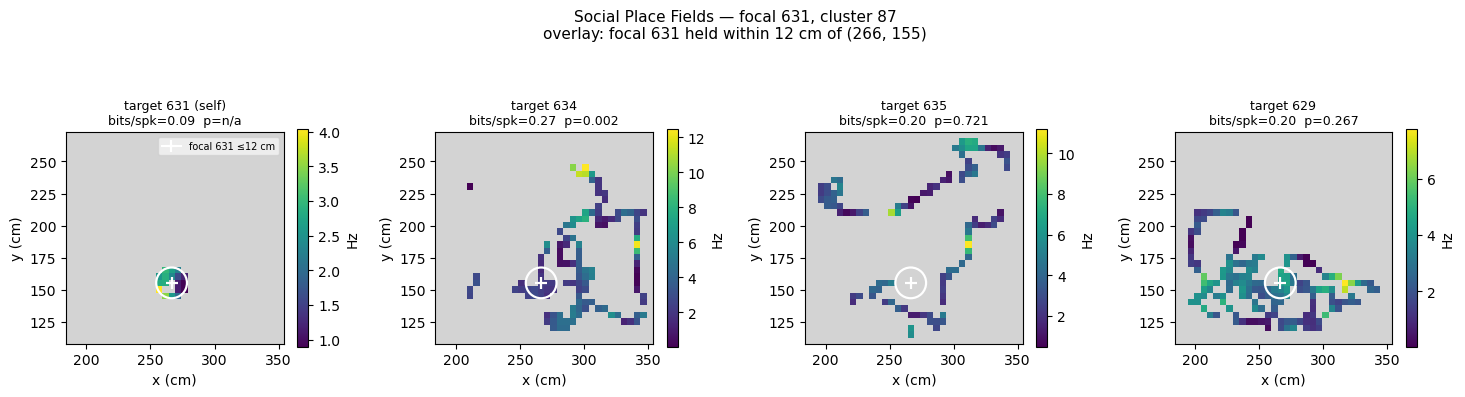

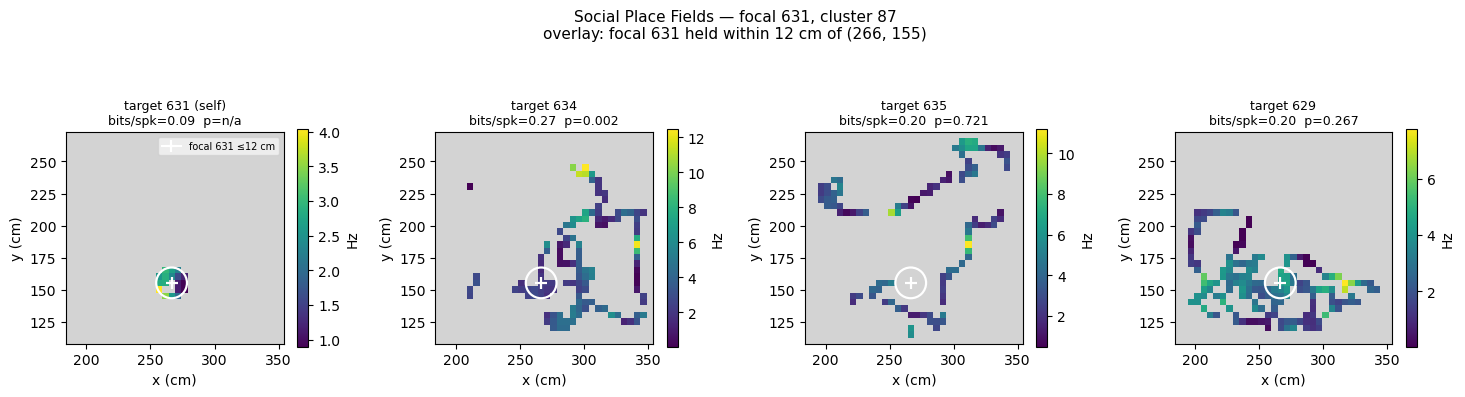

In [10]:
# Side-by-side maps for a cell that survived. Under the stratum the overlay
# becomes the disc the focal animal was confined to, and the self panel should
# be empty outside it — the positive control, visible at a glance.
survivors = partners[partners['survives_stratum']]['cluster_id'].tolist()
cid = int(survivors[0]) if survivors else int(comparison.table['cluster_id'].iloc[0])

sp.plot_rate_maps_grid(comparison.unrestricted, cluster_id=cid)   # focal free
sp.plot_rate_maps_grid(comparison.stratified, cluster_id=cid)     # focal pinned